# DATA-511: Homework Assignment 7

## Instructions

- This homework assignment is worth **59** points. 
- Please strive for clarity and organization.
- **AI Usage**:
   - AI use is strictly **prohibited** for conceptual exercises.
   - For applied (Python) exercises, you may only use AI for **debugging**. Do not use AI to generate answers.
- **Due Date: November 6, 2026, by 11:59 PM.**

# Exercise 1 (3 points)

What does the Central Limit Theorem support in simulation results?

- (a) Independence of variables
- (b) Linear regression validity
- (c) Normality of sampling distribution
- (d) Convergence of time series
- (e) All of the above

C)

# Exercise 2 (4 points)

What does convergence in a simulation indicate?

Convergence in a simulation indicates that the results stabilize as the number of iterations increases. This means that additional simulations produce little change in the estimated value, suggesting that the simulation has reached a reliable result.

# Exercise 3 (5 points)

Simulate 10,000 rolls of a fair 6-sided die and plot the frequency of each outcome.

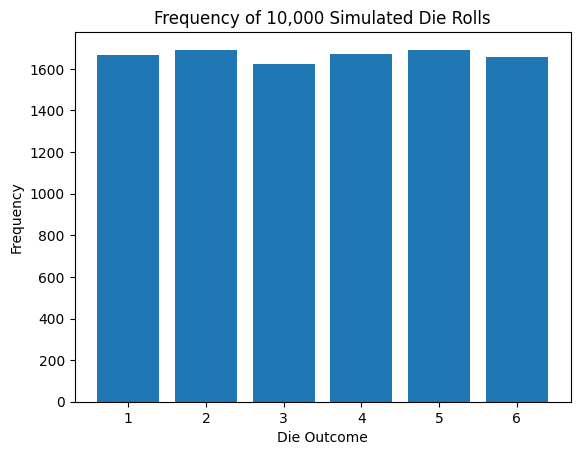

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
rolls = np.random.randint(1, 7, 10000)

outcomes, counts = np.unique(rolls, return_counts=True)

plt.bar(outcomes, counts)
plt.xlabel("Die Outcome")
plt.ylabel("Frequency")
plt.title("Frequency of 10,000 Simulated Die Rolls")
plt.xticks(range(1, 7))
plt.show()

# Exercise 4 (4 points)

What is the key limitation of changing multiple coefficients in a simulation at once?

Changing multiple coefficients at once makes it difficult to determine which individual coefficient caused a change in the simulation results. It also makes it harder to identify the effect of each variable. Changing one coefficient at a time helps isolate its impact and makes the results easier to interpret.

# Exercise 5 (3 points)

What does the burn-in period refer to in simulations?

- (a) The time it takes to prepare the script
- (b) The warm-up iterations before steady-state is reached
- (c) The errors at the end of simulation
- (d) A failed simulation
- (e) None of the above

B)

# Exercise 6 (7 points)

Create a trace plot showing convergence of mean die rolls over 5000 iterations.

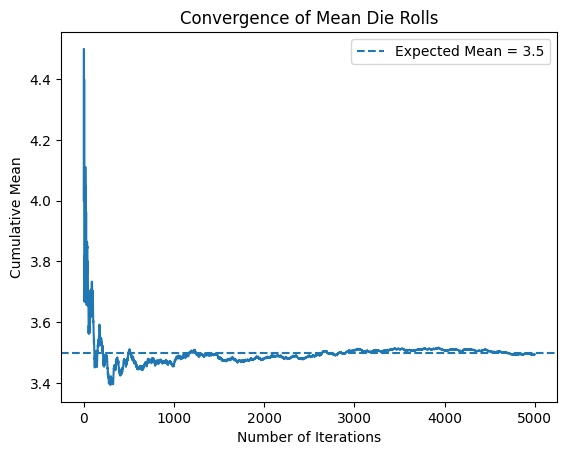

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

rolls = np.random.randint(1, 7, 5000)

cumulative_mean = np.cumsum(rolls) / np.arange(1, 5001)

plt.plot(cumulative_mean)
plt.axhline(y=3.5, linestyle="--", label="Expected Mean = 3.5")
plt.xlabel("Number of Iterations")
plt.ylabel("Cumulative Mean")
plt.title("Convergence of Mean Die Rolls")
plt.legend()
plt.show()

# Exercise 7 (3 points)

In simulation, what kind of variables does the triangular distribution model best?

- (a) Bounded continuous variables with known extremes and mode
- (b) Binary
- (c) Discrete uniform
- (d) Time-based events
- (e) All of the above

A)

# Exercise 8 (7 points)

Simulate 1000 iterations of annualized return over 10 years assuming yearly returns follow a normal distribution with 7% mean and 15% standard deviation. Visualize the returns with a histogram.

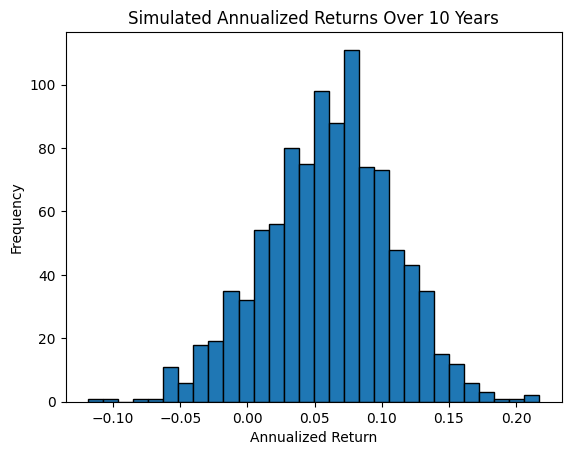

In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

returns = np.random.normal(0.07, 0.15, (1000, 10))

annualized_returns = np.prod(1 + returns, axis=1)**(1/10) - 1

plt.hist(annualized_returns, bins=30, edgecolor="black")
plt.xlabel("Annualized Return")
plt.ylabel("Frequency")
plt.title("Simulated Annualized Returns Over 10 Years")
plt.show()

# Exercise 9 (8 points)

Perform bootstrapping to estimate the standard error of a linear regression coefficient. Consider the below code snippet:

```
import pandas as pd

# Generate sample data
np.random.seed(1)
x = np.random.rand(100)
y = 2 * x + np.random.normal(0, 0.1, 100)
df = pd.DataFrame({'x': x, 'y': y})

```

Take 1,000 bootstrap samples from `df`. For each bootstrap sample, estimate the slope of the line and store the values in a list. Visualize the estimated slopes using a histogram and report the standard deviation of these estimated slopes.

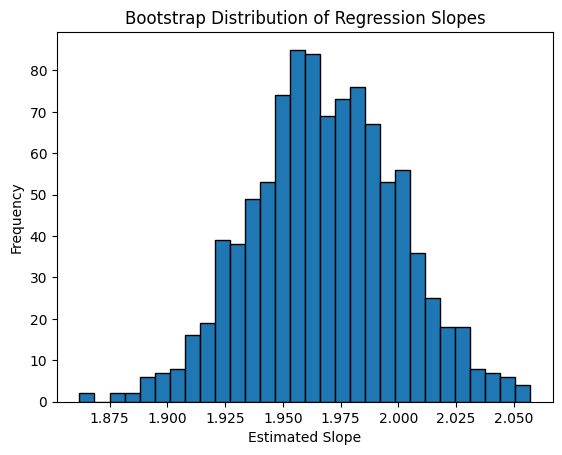

Standard Error of Slope: 0.031856144710303735


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(1)

x = np.random.rand(100)
y = 2 * x + np.random.normal(0, 0.1, 100)

df = pd.DataFrame({'x': x, 'y': y})

slopes = []

for i in range(1000):
    sample = df.sample(n=100, replace=True)
    slope = np.polyfit(sample['x'], sample['y'], 1)[0]
    slopes.append(slope)

standard_error = np.std(slopes, ddof=1)

plt.hist(slopes, bins=30, edgecolor="black")
plt.xlabel("Estimated Slope")
plt.ylabel("Frequency")
plt.title("Bootstrap Distribution of Regression Slopes")
plt.show()

print("Standard Error of Slope:", standard_error)

# Exercise 10 (3 points)

An analyst re-runs a pricing model at prices of \$5, \$6, and \$7 while keeping the estimated price elasticity fixed, and compares the resulting revenue across the three options. Which type of analysis is this?

- (a) Sensitivity analysis
- (b) What-if analysis
- (c) Bootstrapping
- (d) Burn-in analysis
- (e) None of the above

B)

# Exercise 11 (4 points)

A manager compares two pricing options and says: "Option A has a higher profit margin than Option B, so Option A is better." Explain why this conclusion may be wrong, and describe how you would decide which option to recommend.

Option A may have a higher profit margin, but that does not necessarily mean it generates higher total profit. Option B could have a lower profit margin but sell a much larger quantity, resulting in greater overall profit.

I would compare the total expected profit of both options by considering selling price, costs, demand, and sales volume. I would recommend the option that generates the highest expected total profit rather than choosing based only on profit margin.

# Exercise 12 (8 points)

A subscription service models the probability that a customer subscribes at price $P$ with a logit take-rate model:

$$Z = \beta_0 + \beta_1 P, \qquad \text{take} = \frac{e^Z}{1 + e^Z},$$

with $\beta_0 = 3.65529739$ and $\beta_1 = -0.559989$. The market size is 10,000,000 potential customers and the acquisition cost is \$1.50 per subscriber. Contribution is `subscribers * (price - acquisition cost)`.

- (a) **What-if analysis (4 points):** For prices from \$3.00 to \$10.00 in steps of \$0.25 (parameters held fixed), compute the contribution at each price. Plot contribution against price and report the price that maximizes contribution.
- (b) **Sensitivity analysis (4 points):** Now suppose $\beta_1$ is uncertain, with $\hat\beta_1 \sim N(-0.559989,\ 0.05^2)$. Draw 1,000 values of $\beta_1$ (use `np.random.default_rng(511)`). For each draw, find the contribution-maximizing price on the same grid. Visualize the 1,000 optimal prices with a histogram and report their mean and standard deviation. Is the recommendation from (a) robust to estimation error?

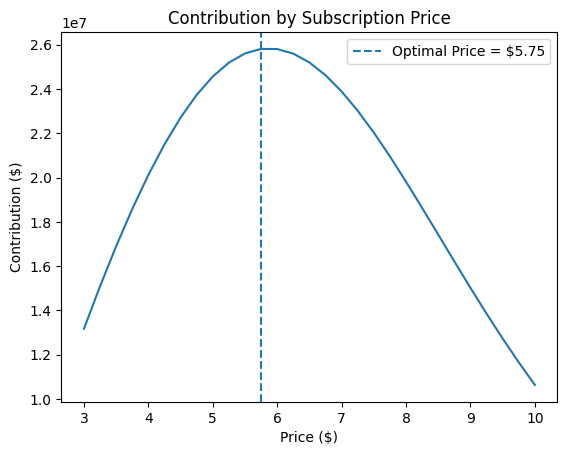

Optimal Price: 5.75
Maximum Contribution: 25804002.95093775


In [5]:
import numpy as np
import matplotlib.pyplot as plt

beta0 = 3.65529739
beta1 = -0.559989
market_size = 10_000_000
acquisition_cost = 1.50

prices = np.arange(3.00, 10.01, 0.25)

z = beta0 + beta1 * prices
take_rate = 1 / (1 + np.exp(-z))

subscribers = market_size * take_rate
contribution = subscribers * (prices - acquisition_cost)

optimal_price = prices[np.argmax(contribution)]
max_contribution = np.max(contribution)

plt.plot(prices, contribution)
plt.xlabel("Price ($)")
plt.ylabel("Contribution ($)")
plt.title("Contribution by Subscription Price")
plt.axvline(optimal_price, linestyle="--", label=f"Optimal Price = ${optimal_price:.2f}")
plt.legend()
plt.show()

print("Optimal Price:", optimal_price)
print("Maximum Contribution:", max_contribution)

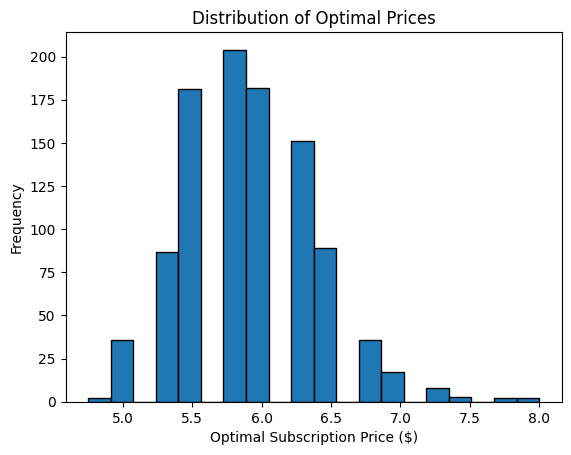

Mean Optimal Price: 5.903
Standard Deviation: 0.48908609181329743


In [6]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(511)

beta1_values = rng.normal(-0.559989, 0.05, 1000)

prices = np.arange(3.00, 10.01, 0.25)

optimal_prices = []

for beta1 in beta1_values:
    z = 3.65529739 + beta1 * prices
    take_rate = 1 / (1 + np.exp(-z))

    subscribers = 10_000_000 * take_rate
    contribution = subscribers * (prices - 1.50)

    optimal_price = prices[np.argmax(contribution)]
    optimal_prices.append(optimal_price)

mean_price = np.mean(optimal_prices)
std_price = np.std(optimal_prices, ddof=1)

plt.hist(optimal_prices, bins=20, edgecolor="black")
plt.xlabel("Optimal Subscription Price ($)")
plt.ylabel("Frequency")
plt.title("Distribution of Optimal Prices")
plt.show()

print("Mean Optimal Price:", mean_price)
print("Standard Deviation:", std_price)